# T4 – Exploratory Data Analysis (EDA)

## Pote et al. (2025) và CooRTweet german_elections

### 1. Mục tiêu

Notebook thực hiện phân tích khám phá dữ liệu phục vụ đề tài Khóa luận tốt nghiệp

Tên tiếng Việt: Phát hiện sớm nhóm tài khoản phối hợp trên mạng xã hội bằng mạng đa lớp có yếu tố thời gian cập nhật tăng dần

Tên tiếng Anh: Early Detection of Coordinated Account Groups on Social Media with Incrementally Updated Time-Aware Multiplex Networks

Các mục tiêu:

1. Kiểm kê tệp dữ liệu và cấu trúc các cột.
2. Giải mã thời điểm từ Twitter Snowflake ID.
3. Kiểm chứng thời gian bằng cột diff_min.
4. Thống kê số chiến dịch và tài khoản IO/normal.
5. Trực quan hóa hoạt động theo thời gian.
6. Xác nhận german_elections không có nhãn ground truth.
7. Đánh giá mức phù hợp và thiên lệch dữ liệu.

### 2. Nguồn dữ liệu

- Pote et al. (2025), Coordinated Reply Attacks in Influence Operations.
- CooRTweet, german_elections, German Federal Election 2021.

In [45]:
%pip install numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
from pathlib import Path
from collections import Counter
import json
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Tìm thư mục gốc của project
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "configs" / "paths.json").exists()
)

# Đọc đường dẫn từ file cấu hình
with open(ROOT / "configs" / "paths.json", encoding="utf-8") as f:
    config = json.load(f)

POTE_DIR = ROOT / config["pote_dir"]
GERMAN_DIR = ROOT / config["german_dir"]
OUTPUT_DIR = ROOT / config["output_dir"]

# Tạo thư mục lưu kết quả
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Tham số EDA
CHUNK_SIZE = 100_000
SNOWFLAKE_EPOCH = 1288834974657

# Kiểm tra đường dẫn
print("Project:", ROOT)
print("Pote:", POTE_DIR, "| Exists:", POTE_DIR.exists())
print("German:", GERMAN_DIR, "| Exists:", GERMAN_DIR.exists())
print("Output:", OUTPUT_DIR)

Project: d:\Cpp\CN-24521602-ThangLH
Pote: d:\Cpp\CN-24521602-ThangLH\data\Coordinated_Reply_Attacks_dataset | Exists: True
German: d:\Cpp\CN-24521602-ThangLH\data\CooRTweet_dataset | Exists: True
Output: d:\Cpp\CN-24521602-ThangLH\reports\T4_EDA_Pote_German


## 1. Khảo sát cấu trúc dữ liệu

### 1.1. Bộ Pote et al. (2025)

Bộ dữ liệu gồm nhiều tệp phục vụ các nghiên cứu RQ1,
RQ2 và RQ3.

Cần xác định:

- Số tệp được cung cấp.
- Tên và kích thước từng tệp.
- Các cột trong mỗi tệp.
- Sự hiện diện của ID tweet, ID tài khoản,
  chiến dịch, nhãn và thông tin thời gian.

Lưu ý: Các bảng có thể chứa những quan sát
trùng nhau nên không được cộng số dòng giữa
các bảng thành tổng số hành động độc lập.

In [47]:
pote_files = sorted(POTE_DIR.rglob("*.csv"))

inventory = []

for path in pote_files:
    sample = pd.read_csv(path, nrows=5, dtype="string")

    inventory.append({
        "File": path.name,
        "Size (MB)": round(path.stat().st_size / 1024**2, 2),
        "Columns": len(sample.columns),
        "Column names": ", ".join(sample.columns)
    })

inventory_df = pd.DataFrame(inventory)

print("Số tệp Pote:", len(pote_files))
display(inventory_df)

inventory_df.to_csv(OUTPUT_DIR / "pote_file_inventory.csv", index=False, encoding="utf-8-sig")

# Xem 5 dòng đầu của từng tệp
for path in pote_files:
    print("\nFILE:", path.name)
    sample = pd.read_csv(path, nrows=5, dtype="string")
    print("Columns:", sample.columns.tolist())
    display(sample)

Số tệp Pote: 5


,File,Size (MB),Columns,Column names
0,poster_tweetid_campaign_type.csv,180.76,6,"poster_tweetid, campaign, replier_userid, repl..."
1,RQ1_time_difference_of_reply.csv,45.50,2,"replier_tweetid, diff_min"
2,RQ2_tweet_classifier_features.csv,7.30,101,"std_retweet_count, range_reply_count, entropy_..."
3,RQ3_replier_classifier_features.csv,313.18,78,"replier_userid, replier_label, age, mean_menti..."
4,RQ3_replier_info.csv,272.83,6,"replier_userid, activity_count, replier_label,..."



FILE: poster_tweetid_campaign_type.csv
Columns: ['poster_tweetid', 'campaign', 'replier_userid', 'replier_label', 'replier_tweetid', 'type']


,poster_tweetid,campaign,replier_userid,replier_label,replier_tweetid,type
0,1174348484973142016,remain,1166809760945098753,0,1174624178554724353,target
1,1174348484973142016,remain,1169162312227479552,0,1174377181000142849,target
2,1174348484973142016,remain,4276713383,0,1174370668735029249,target
3,1174348484973142016,remain,768843654672908288,0,1174365657808494599,target
4,1184015152846376960,remain,3092117320,0,1185270126872018944,target



FILE: RQ1_time_difference_of_reply.csv
Columns: ['replier_tweetid', 'diff_min']


,replier_tweetid,diff_min
0,312077262310739969,1
1,312077921084928000,1
2,312090869748617216,1
3,312091804210184192,1
4,312092998789894144,2


... (2 outputs left out)


FILE: RQ3_replier_classifier_features.csv
Columns: ['replier_userid', 'replier_label', 'age', 'mean_mention_count', 'min_mention_count', '25%_mention_count', '50%_mention_count', '75%_mention_count', 'max_mention_count', 'range_mention_count', 'iqr_mention_count', 'entropy_mention_count', 'mean_hashtags_count', 'min_hashtags_count', '25%_hashtags_count', '50%_hashtags_count', '75%_hashtags_count', 'max_hashtags_count', 'range_hashtags_count', 'iqr_hashtags_count', 'entropy_hashtags_count', 'mean_num_url', 'min_num_url', '25%_num_url', '50%_num_url', '75%_num_url', 'max_num_url', 'range_num_url', 'iqr_num_url', 'entropy_num_url', 'mean_diff_min', 'min_diff_min', '25%_diff_min', '50%_diff_min', '75%_diff_min', 'max_diff_min', 'range_diff_min', 'iqr_diff_min', 'entropy_diff_min', 'followers_ratio', 'following_ratio', 'mean_reply_count', 'min_reply_count', '25%_reply_count', '50%_reply_count', '75%_reply_count', 'max_reply_count', 'range_reply_count', 'iqr_reply_count', 'entropy_reply_cou

,replier_userid,replier_label,age,mean_mention_count,min_mention_count,25%_mention_count,50%_mention_count,75%_mention_count,max_mention_count,range_mention_count,...,activity_rate,mean_cosine,min_cosine,25%_cosine,50%_cosine,75%_cosine,max_cosine,range_cosine,iqr_cosine,entropy_cosine
0,1000000209278021632,0,0.05749604714675866,2.0,2.0,2.0,2.0,2.0,2.0,0,...,61.5,0.07068441063165665,-0.15000000596046448,-0.009999999776482582,0.05000000074505806,0.11999999731779099,0.6499999761581421,0.7999999821186066,0.12999999709427357,5.168538229238742
1,1000000283106250754,0,1.3333607124034033,1.0,1.0,1.0,1.0,1.0,1.0,0,...,151.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1000001637711335425,0,0.008213721020965523,1.0,1.0,1.0,1.0,1.0,1.0,0,...,4.166666666666666,0.17628204822540283,-0.38999998569488525,0.1074999999254942,0.17000000178813934,0.2524999976158142,0.49000000953674316,0.8799999952316284,0.14499999769032001,5.118637134404369
3,1000001923234369536,0,0.024641163062896567,1.0,1.0,1.0,1.0,1.0,1.0,0,...,11.833333333333334,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1000002261119045632,0,0.027379070069885075,1.0,1.0,1.0,1.0,1.0,1.0,0,...,12.166666666666666,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



FILE: RQ3_replier_info.csv
Columns: ['replier_userid', 'activity_count', 'replier_label', 'following_count', 'followers_count', 'age']


,replier_userid,activity_count,replier_label,following_count,followers_count,age
0,12148412,464.0,1,<NA>,<NA>,11.504685243365708
1,13739162,82.0,1,<NA>,<NA>,11.066620122247548
2,14596653,6.0,1,17.0,170.0,11.069358029254536
3,14800962,4626.0,1,<NA>,<NA>,10.718905932360007
4,15059867,2234.0,1,<NA>,<NA>,9.623743129564604


## 2. Khôi phục thời gian từ Twitter Snowflake ID

Twitter Snowflake ID chứa thông tin thời gian
tạo tweet trong các bit cao.

Công thức:

timestamp_ms = (tweet_id >> 22) + 1288834974657

Trong đó:

- tweet_id: định danh tweet dạng số nguyên.
- `>>` 22: phép dịch bit phải 22 vị trí.
- 1288834974657: Twitter epoch, đơn vị mili-giây.
- timestamp_ms: Unix timestamp tính bằng mili-giây.

Chuyển timestamp_ms sang datetime theo UTC.

Lưu ý:

- Không đọc ID dưới dạng float.
- Không dùng công thức cho ID tài khoản.
- Không dùng công thức cho post_id ẩn danh
  của german_elections.

In [48]:
def snowflake_to_ms(tweet_id):
    if pd.isna(tweet_id):
        return None

    tweet_id = str(tweet_id).strip()

    if not tweet_id.isdigit():
        return None

    return (int(tweet_id) >> 22) + SNOWFLAKE_EPOCH


def decode_tweet_ids(series):
    milliseconds = series.map(snowflake_to_ms)

    return pd.to_datetime(milliseconds, unit="ms", utc=True, errors="coerce")

## 3. Thống kê chiến dịch IO

Mục tiêu là xác định số chiến dịch được biểu diễn trong dữ liệu công bố. Chỉ đếm chiến dịch khi có cột định danh chiến dịch rõ ràng.

Phân biệt:

- campaign_id / campaign_name: định danh chiến dịch.
- campaign_type: loại chiến dịch, không mặc nhiên tương ứng với từng chiến dịch.

Số chiến dịch sử dụng trong bài báo gốc cũng không mặc nhiên bằng số chiến dịch có thể truy xuất được từ các tệp CSV công bố.

In [49]:
poster_path = POTE_DIR / "poster_tweetid_campaign_type.csv"

campaigns = set()
types = Counter()

for chunk in pd.read_csv(poster_path, dtype="string", chunksize=CHUNK_SIZE):
    # Đếm số chiến dịch duy nhất
    campaigns.update(chunk["campaign"].dropna().unique())

    # Đếm số bản ghi theo loại chiến dịch
    types.update(chunk["type"].dropna().value_counts().to_dict())

print("Số chiến dịch:", len(campaigns))
print("Danh sách chiến dịch:", sorted(campaigns))

print("\nPhân bố theo loại chiến dịch:")
display(pd.DataFrame(types.items(), columns=["Campaign type", "Records"]))

Số chiến dịch: 29
Danh sách chiến dịch: ['CNHU_0621', 'MX_0621', 'Tanzania_0621', 'Venezuela_0621', 'china_052020', 'china_082019', 'cuba_082020', 'ecuador_082019', 'egypt_022020', 'egypt_uae_082019', 'honduras_022020', 'indonesia_022020', 'ira', 'iran_201901_1', 'iran_201906', 'iran_202012', 'iranian', 'qatar_082020', 'remain', 'russia_201901_1', 'sa_eg_ae_022020', 'saudi_arabia_112019', 'serbia_022020', 'spain_082019', 'thailand_092020', 'turkey_052020', 'uae_082019', 'uganda_0621', 'venezuela_201901']

Phân bố theo loại chiến dịch:


,Campaign type,Records
0,target,2160484
1,control,512607


## 4. Phân bố tài khoản IO và normal

### 4.1. Mục tiêu

Phân tích phân bố tài khoản phản hồi theo hai nhóm IO (Information Operation) và normal trong bộ dữ liệu Pote et al. (2025).

Sử dụng file RQ3_replier_info.csv với hai cột:

- replier_userid: Định danh tài khoản phản hồi.
- replier_label: Nhãn phân loại tài khoản.

Các nội dung phân tích:

- Thống kê số tài khoản IO và normal duy nhất.
- Tính tỷ lệ phần trăm của từng nhóm.
- Trực quan hóa phân bố tài khoản bằng biểu đồ cột.
- Kiểm tra sự mất cân bằng giữa hai nhóm.

Số lượng tài khoản được tính dựa trên ID duy nhất (replier_userid), tránh đếm trùng khi một tài khoản xuất hiện trong nhiều bản ghi.

### 4.2. Giới hạn

- Nhãn IO phản ánh tư cách thuộc chiến dịch information operation theo nguồn dữ liệu, không đồng nghĩa với việc mọi bài đăng của tài khoản đều sai lệch hoặc độc hại.
- Phân bố IO/normal có thể chịu ảnh hưởng từ phương pháp thu thập và lựa chọn mẫu của bộ dữ liệu.
- Kết quả thống kê chỉ phản ánh các tài khoản xuất hiện trong dữ liệu được công bố, không đại diện cho toàn bộ người dùng mạng xã hội.

Các nhãn: <StringArray>
['1', '0']
Length: 2, dtype: string

Số tài khoản theo nhãn:
replier_label
0    2974876
1      19436
Name: replier_userid, dtype: int64

Tổng số tài khoản duy nhất: 2994299


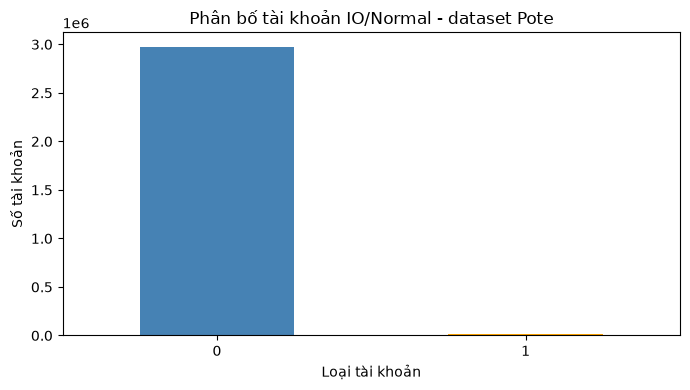

In [50]:
df = pd.read_csv(POTE_DIR / "RQ3_replier_info.csv", usecols=["replier_userid", "replier_label"], dtype="string")

# Kiểm tra giá trị nhãn
print("Các nhãn:", df["replier_label"].unique())

# Đếm số tài khoản duy nhất theo nhãn
accounts = df.dropna().drop_duplicates()

counts = accounts.groupby("replier_label")["replier_userid"].nunique()

print("\nSố tài khoản theo nhãn:")
print(counts)

print("\nTổng số tài khoản duy nhất:", accounts["replier_userid"].nunique())

ax = counts.plot(kind="bar",figsize=(7, 4),color=["steelblue", "orange"])

ax.set_title("Phân bố tài khoản IO/Normal - dataset Pote")
ax.set_xlabel("Loại tài khoản")
ax.set_ylabel("Số tài khoản")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "pote_account_distribution.png", dpi=160)
plt.show()


In [51]:
# Tìm tài khoản có nhiều nhãn
conflict_ids = conflicts[conflicts > 1].index

# Hiển thị tài khoản và các nhãn tương ứng
conflict_df = df[df["replier_userid"].isin(conflict_ids)].sort_values("replier_userid")

print("Số tài khoản mâu thuẫn:", len(conflict_ids))
display(conflict_df)

Số tài khoản mâu thuẫn: 13


,replier_userid,replier_label
10013,1009341466865364992,1
86216,1009341466865364992,0
117464,1014179731019829250,0
117463,1014179731019829250,0
10122,1014179731019829250,1
...,...,...
5591135,949899497748000768,0
5591145,949899497748000768,0
5898247,999130218408357888,0
9738,999130218408357888,1


## 5. Kiểm chứng thời gian bằng diff_min

Kiểm tra xem thời gian giải mã từ Tweet ID có tương thích với độ trễ được cung cấp hay không.

Giả thuyết kiểm tra: diff_calculated_min = (timestamp_reply - timestamp_target) / 60

So sánh với diff_min khi cả hai Tweet ID nằm trong cùng bản ghi và thực sự tương ứng với tweet gốc và reply.

Các chỉ số:

- Số cặp kiểm chứng hợp lệ.
- Sai số tuyệt đối trung bình (MAE).
- Tỷ lệ sai số không quá 0,5 phút.
- Tỷ lệ sai số không quá 1 phút.
- Số trường hợp reply sớm hơn target.

Nếu không khớp, cần kiểm tra ý nghĩa thực tế của diff_min, cặp ID, phép làm tròn và cách xây dựng dữ liệu.

In [52]:
rq1 = pd.read_csv( POTE_DIR / "RQ1_time_difference_of_reply.csv", dtype="string")

poster = pd.read_csv(POTE_DIR / "poster_tweetid_campaign_type.csv", usecols=["poster_tweetid", "replier_tweetid"], dtype="string" ).drop_duplicates()

# Ghép dữ liệu theo Reply ID
df = rq1.merge(poster, on="replier_tweetid", how="inner")

# Giải mã thời gian từ Tweet ID
t_reply = decode_tweet_ids(df["replier_tweetid"])
t_target = decode_tweet_ids(df["poster_tweetid"])

# Tính khoảng thời gian (phút)
df["calculated_min"] = ((t_reply - t_target).dt.total_seconds() / 60)

df["diff_min"] = pd.to_numeric(df["diff_min"], errors="coerce")
df["error_min"] = (df["calculated_min"] - df["diff_min"]).abs()

# Thống kê sai số
valid = df["error_min"].dropna()

print("Số cặp hợp lệ:", len(valid))
print("MAE (phút):", valid.mean())
print("Khớp trong 0.5 phút:", (valid <= 0.5).mean() * 100, "%")
print("Khớp trong 1 phút:", (valid <= 1).mean() * 100, "%")

display(df[["replier_tweetid", "poster_tweetid", "diff_min", "calculated_min", "error_min"]].head())

Số cặp hợp lệ: 2147936
MAE (phút): 9855.46256240556
Khớp trong 0.5 phút: 1.1591593045602848 %
Khớp trong 1 phút: 1.9654682448639067 %


,replier_tweetid,poster_tweetid,diff_min,calculated_min,error_min
0,312077262310739969,312076889168683008,1,1.482733,0.482733
1,312077921084928000,312076889168683008,1,4.100467,3.100467
2,312090869748617216,312076889168683008,1,55.553833,54.553833
3,312091804210184192,312076889168683008,1,59.267050,58.26705
4,312092998789894144,312076889168683008,2,64.013883,62.013883


## 6. Phân tích hoạt động theo thời gian của Pote

Mục tiêu:

- Khôi phục chuỗi thời gian từ ID tweet.
- Tổng hợp số bản ghi theo ngày UTC.
- Quan sát các giai đoạn hoạt động cao và thấp.
- Nhận diện các khoảng thời gian tập trung hoạt động.

Chỉ sử dụng một bảng hành động trong mỗi biểu đồ để hạn chế đếm lặp giữa RQ1, RQ2 và RQ3.

Hoạt động quan sát được trong dữ liệu đã chọn mẫu không mặc nhiên đại diện toàn bộ chiến dịch IO.

Ngày đầu: 2013-03-14 00:00:00+00:00
Ngày cuối: 2023-04-05 00:00:00+00:00


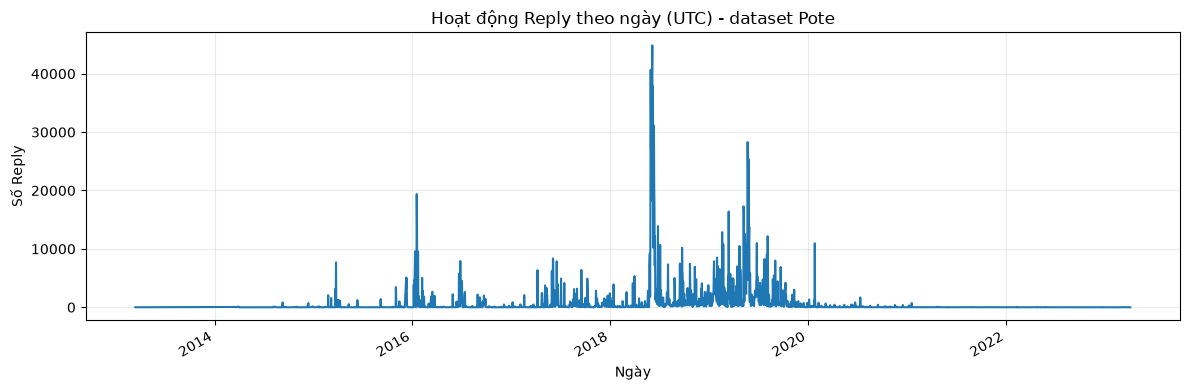

In [53]:
df = pd.read_csv(
    POTE_DIR / "RQ1_time_difference_of_reply.csv", usecols=["replier_tweetid"], dtype="string")

# Giải mã thời gian từ Tweet ID
df["timestamp"] = decode_tweet_ids(df["replier_tweetid"])

# Thống kê số reply theo ngày (UTC)
activity = (df.dropna(subset=["timestamp"]).groupby(df["timestamp"].dt.floor("D")).size())

print("Ngày đầu:", activity.index.min())
print("Ngày cuối:", activity.index.max())

ax = activity.plot(figsize=(12, 4))

ax.set_title("Hoạt động Reply theo ngày (UTC) - dataset Pote")
ax.set_xlabel("Ngày")
ax.set_ylabel("Số Reply")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pote_activity_daily.png", dpi=160)
plt.show()

activity.rename("reply_count").to_csv(OUTPUT_DIR / "pote_daily_counts.csv")


## 7. Khảo sát CooRTweet german_elections

german_elections là dữ liệu ẩn danh, đa nền tảng và đa loại nội dung về bầu cử liên bang Đức 2021.

Dữ liệu hỗ trợ nghiên cứu mạng phối hợp dựa trên URL, hashtag, domain và hình ảnh.

Cần kiểm chứng:

1. Số bản ghi, số tài khoản.
2. Khoảng thời gian hoạt động.
3. Phân bố nền tảng Twitter/Facebook.
4. Các loại nội dung hiện diện.
5. Sự vắng mặt của nhãn ground truth.

post_id trong bộ này đã được ẩn danh và không được giải mã bằng Twitter Snowflake.

In [54]:
german_path = GERMAN_DIR / "german_elections.csv"
german = pd.read_csv(german_path, dtype="string")

# Thông tin tổng quan
print("Số bản ghi:", len(german))
print("Số cột:", len(german.columns))
print("Số tài khoản:", german["account_id"].nunique())
print("Danh sách cột:", german.columns.tolist())

# Kiểm tra thời gian
german_time = pd.to_datetime(
    pd.to_numeric(german["timestamp"], errors="coerce"),
    unit="s",
    utc=True,
    errors="coerce"
)

print("\nThời gian bắt đầu:", german_time.min())
print("Thời gian kết thúc:", german_time.max())

display(german.head())

Số bản ghi: 218971
Số cột: 7
Số tài khoản: 58317
Danh sách cột: ['account_id', 'post_id', 'url_id', 'hashtag_id', 'domain_id', 'phash_id', 'timestamp']

Thời gian bắt đầu: 2021-08-15 22:01:32+00:00
Thời gian kết thúc: 2021-09-26 23:59:05+00:00


,account_id,post_id,url_id,hashtag_id,domain_id,phash_id,timestamp
0,fb_12670,129235,23678,<NA>,3498,<NA>,1629589836
1,fb_5966,84441,<NA>,<NA>,6756,<NA>,1629589069
2,fb_5966,84443,29871,<NA>,5534,<NA>,1629589050
3,fb_5966,84445,<NA>,<NA>,<NA>,9280,1629589022
4,fb_5966,84446,30435,<NA>,5639,<NA>,1629589009


## 8. Trực quan hóa german_elections

Thực hiện:

- Biểu đồ số bài đăng theo ngày UTC.
- So sánh mức hoạt động Twitter/Facebook.
- Đo độ phủ của URL, hashtag, domain và phash.

Các trường *_id là định danh nội dung đã ẩn danh, không phải nhãn phối hợp.

Biểu đồ phản ánh hoạt động quan sát được, không chứng minh tài khoản phối hợp hay độc hại.

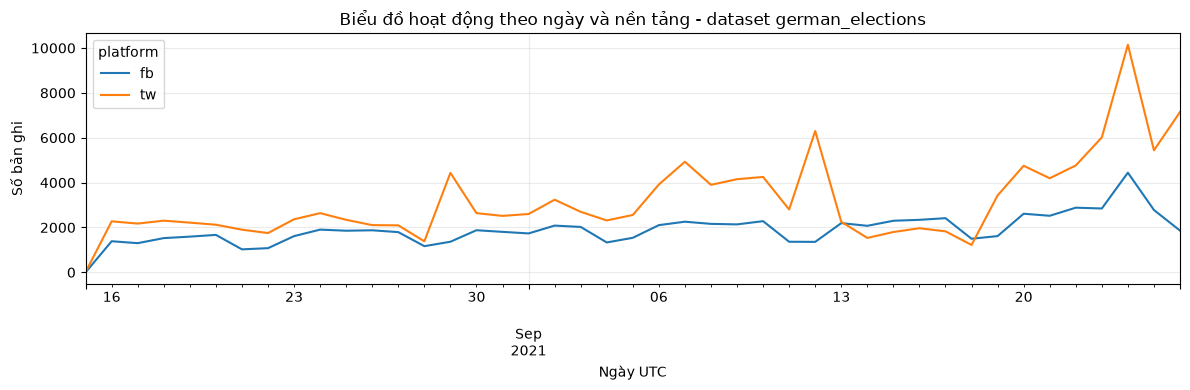

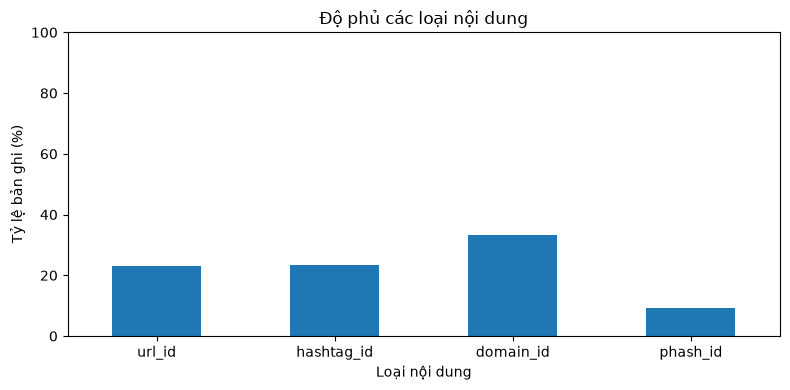

,Coverage (%)
url_id,23.192569
hashtag_id,23.379352
domain_id,33.435478
phash_id,9.164684


In [55]:
platform = (
    german["account_id"]
    .str.extract(r"^([^_]+)_", expand=False)
    .fillna("other")
    .str.lower()
    )

daily = pd.DataFrame({
    "day": german_time.dt.floor("D"),
    "platform": platform
    })

daily_platform = (
    daily.groupby(["day", "platform"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

ax = daily_platform.plot(figsize=(12, 4))

ax.set_title("Biểu đồ hoạt động theo ngày và nền tảng - dataset german_elections")
ax.set_xlabel("Ngày UTC")
ax.set_ylabel("Số bản ghi")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "german_activity_daily.png", dpi=160)
plt.show()

daily_platform.to_csv(OUTPUT_DIR / "german_daily_platform.csv")

modality_columns = ["url_id", "hashtag_id", "domain_id", "phash_id"]

coverage = (german[modality_columns].notna().mean().mul(100))

ax = coverage.plot(kind="bar",figsize=(8, 4))

ax.set_title("Độ phủ các loại nội dung")
ax.set_xlabel("Loại nội dung")
ax.set_ylabel("Tỷ lệ bản ghi (%)")
ax.set_ylim(0, 100)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "german_modality_coverage.png", dpi=160)

plt.show()

display(coverage.rename("Coverage (%)").to_frame())